Comprehensive visualization generated.


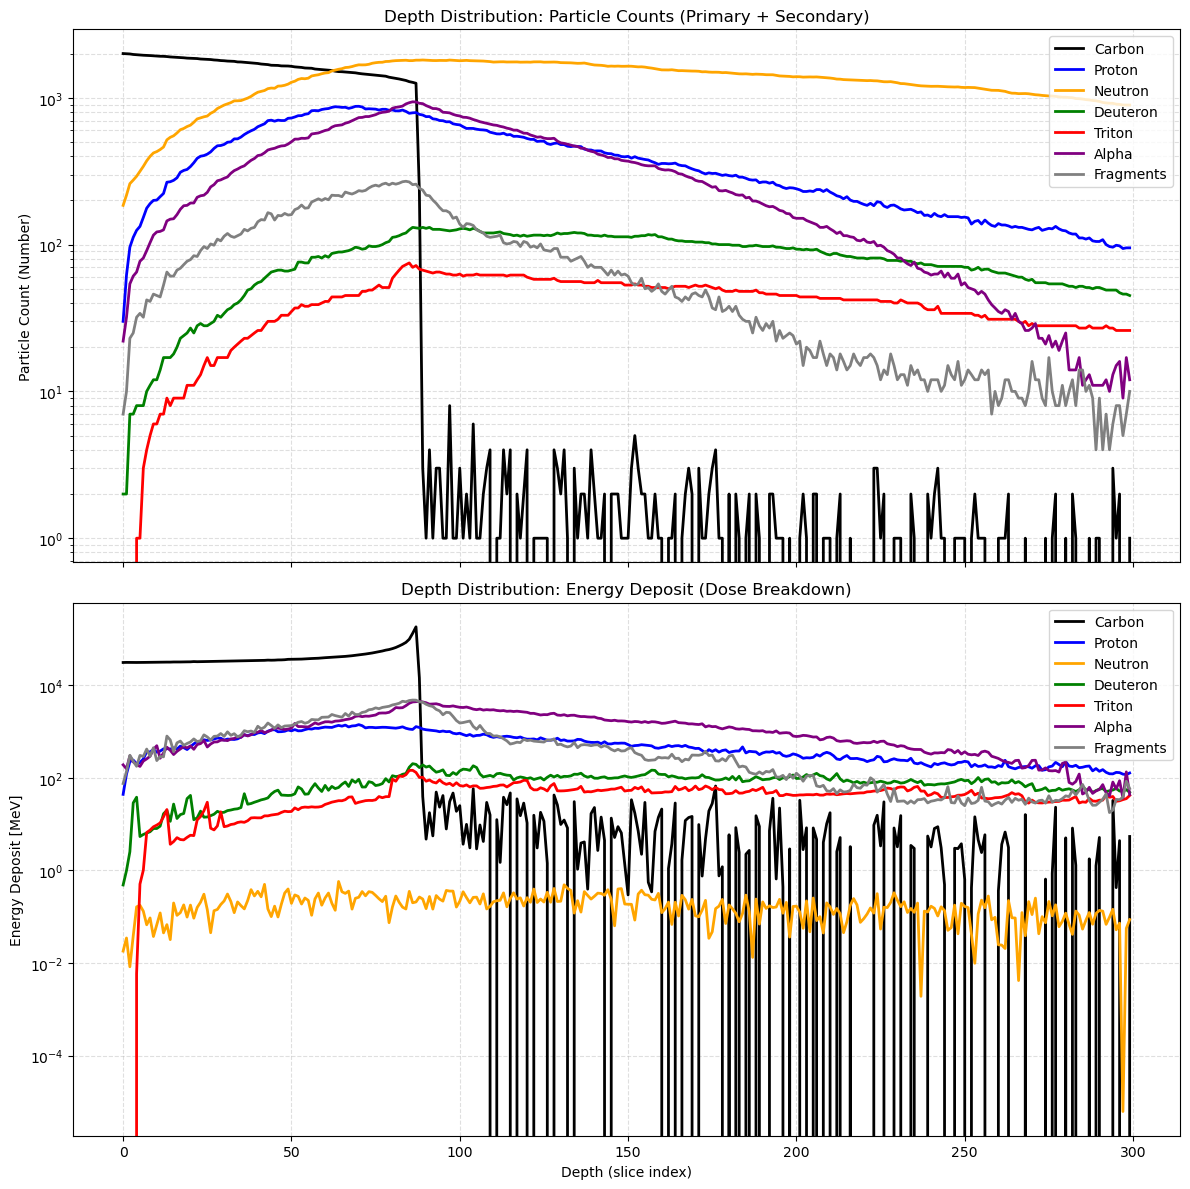

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('QGSP_INCLXX_HP.csv')
df.columns = [c.strip() for c in df.columns]

def parse_map(details_str, val_type=float):
    if pd.isna(details_str) or not isinstance(details_str, str):
        return {}
    pairs = details_str.strip().split(';')
    result = {}
    for p in pairs:
        if ':' in p:
            parts = p.split(':')
            if len(parts) == 2:
                name, val = parts
                try:
                    result[name.strip()] = val_type(val.strip())
                except ValueError:
                    continue
    return result

# Grouping logic
def get_grouped_data(parsed_dict):
    c_val = sum(v for k, v in parsed_dict.items() if k.startswith('C'))
    p_val = parsed_dict.get('proton', 0)
    n_val = parsed_dict.get('neutron', 0)
    d_val = parsed_dict.get('deuteron', 0)
    t_val = parsed_dict.get('triton', 0)
    a_val = parsed_dict.get('alpha', 0)
    
    specifics = ['proton', 'neutron', 'deuteron', 'triton', 'alpha']
    leptons_gammas = ['e-', 'e+', 'gamma']
    
    f_val = 0
    for k, v in parsed_dict.items():
        if k.startswith('C'): continue
        if k in specifics: continue
        if k in leptons_gammas: continue
        f_val += v
        
    return pd.Series({'C': c_val, 'p': p_val, 'n': n_val, 'd': d_val, 't': t_val, 'alpha': a_val, 'Frag': f_val})

# Process Counts
counts_df = df['secondary_counts'].apply(lambda x: parse_map(x, int)).apply(get_grouped_data)
# Add primaries to Carbon count
counts_df['C'] += df['primaries']

# Process Energy
energy_df = df['energy_details'].apply(lambda x: parse_map(x, float)).apply(get_grouped_data)

# Visualization
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12), sharex=True)

labels = ['Carbon', 'Proton', 'Neutron', 'Deuteron', 'Triton', 'Alpha', 'Fragments']
keys = ['C', 'p', 'n', 'd', 't', 'alpha', 'Frag']
colors = ['black', 'blue', 'orange', 'green', 'red', 'purple', 'gray']

# Subplot 1: Particle Counts
for k, label, color in zip(keys, labels, colors):
    ax1.plot(df['copyNo'], counts_df[k], label=label, color=color, linewidth=2)
ax1.set_yscale('log')
ax1.set_ylabel('Particle Count (Number)')
ax1.set_title('Depth Distribution: Particle Counts (Primary + Secondary)')
ax1.grid(True, which='both', linestyle='--', alpha=0.4)
ax1.legend(loc='upper right')

# Subplot 2: Energy Deposit
for k, label, color in zip(keys, labels, colors):
    ax2.plot(df['copyNo'], energy_df[k], label=label, color=color, linewidth=2)
ax2.set_yscale('log')
ax2.set_ylabel('Energy Deposit [MeV]')
ax2.set_xlabel('Depth (slice index)')
ax2.set_title('Depth Distribution: Energy Deposit (Dose Breakdown)')
ax2.grid(True, which='both', linestyle='--', alpha=0.4)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig('comprehensive_analysis.png')

print("Comprehensive visualization generated.")